Import pandas and numpy opens the 

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

In [44]:
import pandas as pd
import numpy as np

In [45]:
file_path = r"C:\PYTHON\Coursework 1\HEA Phase DataSet v1d.csv"
df = pd.read_csv(file_path, encoding ="latin-1")
print(df.shape)
# df.head(20) displays first (number) rows of the dataframe
print(df.head()) #displays first (number) rows of the dataframe, 5 if not specified

(1361, 53)
     Alloy ID         Alloy         Al   Co   Cr   Fe   Ni   Cu   Mn  \
0  Alloy 0000   Al0.5NbTaTiV  0.111111  0.0  0.0  0.0  0.0  0.0  0.0   
1  Alloy 0001  Al0.75MoNbTiV  0.157895  0.0  0.0  0.0  0.0  0.0  0.0   
2  Alloy 0002  Al0.25MoNbTiV  0.058824  0.0  0.0  0.0  0.0  0.0  0.0   
3  Alloy 0003  Al0.25NbTaTiV  0.058824  0.0  0.0  0.0  0.0  0.0  0.0   
4  Alloy 0004   Al0.2MoTaTiV  0.047619  0.0  0.0  0.0  0.0  0.0  0.0   

         Ti  ...  Quenching  HPR  Microstructure_  Multiphase  IM_Structure  \
0  0.222222  ...        NaN  NaN              BCC           S           NaN   
1  0.210526  ...        NaN  NaN              BCC           S           NaN   
2  0.235294  ...        NaN  NaN              BCC           S           NaN   
3  0.235294  ...        NaN  NaN              BCC           S           NaN   
4  0.238095  ...        NaN  NaN              BCC           S           NaN   

   Microstructure  Phases                              References  \
0           

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1361 entries, 0 to 1360
Data columns (total 53 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alloy ID              1360 non-null   str    
 1   Alloy                 1360 non-null   str    
 2   Al                    1360 non-null   float64
 3   Co                    1360 non-null   float64
 4   Cr                    1360 non-null   float64
 5   Fe                    1360 non-null   float64
 6   Ni                    1360 non-null   float64
 7   Cu                    1360 non-null   float64
 8   Mn                    1360 non-null   float64
 9   Ti                    1360 non-null   float64
 10  V                     1360 non-null   float64
 11  Nb                    1360 non-null   float64
 12  Mo                    1360 non-null   float64
 13  Zr                    1360 non-null   float64
 14  Hf                    1360 non-null   float64
 15  Ta                    1360 non-n

In [ ]:
df.describe() #provides a summary of the statistics for numerical columns in the DataFrame, including count, mean, standard deviation, minimum, maximum, and quartiles. 

,Al,Co,Cr,Fe,Ni,Cu,Mn,Ti,V,Nb,...,Tm,n.Para,Atom.Size.Diff,Elect.Diff,VEC,Homogenization_Temp,Homogenization_Time,Annealing_Time_(min),Unnamed: 51,Unnamed: 52
count,1360.000000,1360.000000,1360.000000,1360.000000,1360.000000,1360.000000,1360.000000,1360.000000,1360.000000,1360.000000,...,1360.000000,1359.000000,1360.000000,1360.000000,1360.000000,571.000000,561.000000,594.000000,0.0,0.0
mean,0.068393,0.115694,0.116987,0.130766,0.132417,0.015553,0.048479,0.088741,0.031342,0.075436,...,1823.725359,9.146608,4.414770,0.159028,6.537999,1145.297723,933.557932,1071.297980,NaN,NaN
std,0.117587,0.123935,0.108737,0.135841,0.128690,0.049680,0.101408,0.120278,0.075292,0.106255,...,430.135657,21.810314,2.291318,0.225247,1.660303,152.978036,969.501052,3172.582625,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,646.934672,0.559007,0.168046,0.015000,3.161339,500.000000,2.000000,0.000000,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1489.329417,2.090463,3.262142,0.110000,4.600000,1100.000000,120.000000,60.000000,NaN,NaN
50%,0.000000,0.100000,0.150000,0.163934,0.166667,0.000000,0.000000,0.000000,0.000000,0.000000,...,1801.200000,4.654402,4.429916,0.122434,7.200000,1200.000000,360.000000,120.000000,NaN,NaN
75%,0.111111,0.200000,0.200000,0.200000,0.222222,0.000000,0.000000,0.200000,0.000000,0.200000,...,2111.996306,8.540000,5.655462,0.147521,8.000000,1200.000000,1440.000000,1440.000000,NaN,NaN
max,0.911392,0.776355,0.400000,0.730665,0.500000,0.250000,0.450000,0.500000,0.625000,0.420000,...,3157.750000,279.277101,19.059548,3.920000,9.500000,1700.000000,3600.000000,60480.000000,NaN,NaN


In [48]:
df.isnull().sum() #identfies the number of missing values

Alloy ID                   1
Alloy                      1
Al                         1
Co                         1
Cr                         1
Fe                         1
Ni                         1
Cu                         1
Mn                         1
Ti                         1
V                          1
Nb                         1
Mo                         1
Zr                         1
Hf                         1
Ta                         1
W                          1
C                          1
Mg                         1
Zn                         1
Si                         1
Re                         1
N                          1
Sc                         1
Li                         1
Sn                         1
Be                         1
Num_of_Elem                1
Density_calc               6
dHmix                      1
dSmix                      1
dGmix                      1
Tm                         1
n.Para                     2
Atom.Size.Diff

In [49]:
df.isnull().sum() / len(df) #this gives the proportion of missing values in each column, which can help identify columns with a high percentage of missing data that may need to be addressed before analysis.

Alloy ID                0.000735
Alloy                   0.000735
Al                      0.000735
Co                      0.000735
Cr                      0.000735
Fe                      0.000735
Ni                      0.000735
Cu                      0.000735
Mn                      0.000735
Ti                      0.000735
V                       0.000735
Nb                      0.000735
Mo                      0.000735
Zr                      0.000735
Hf                      0.000735
Ta                      0.000735
W                       0.000735
C                       0.000735
Mg                      0.000735
Zn                      0.000735
Si                      0.000735
Re                      0.000735
N                       0.000735
Sc                      0.000735
Li                      0.000735
Sn                      0.000735
Be                      0.000735
Num_of_Elem             0.000735
Density_calc            0.004409
dHmix                   0.000735
dSmix     

In [50]:
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt
#visualize missing values using a heatmap

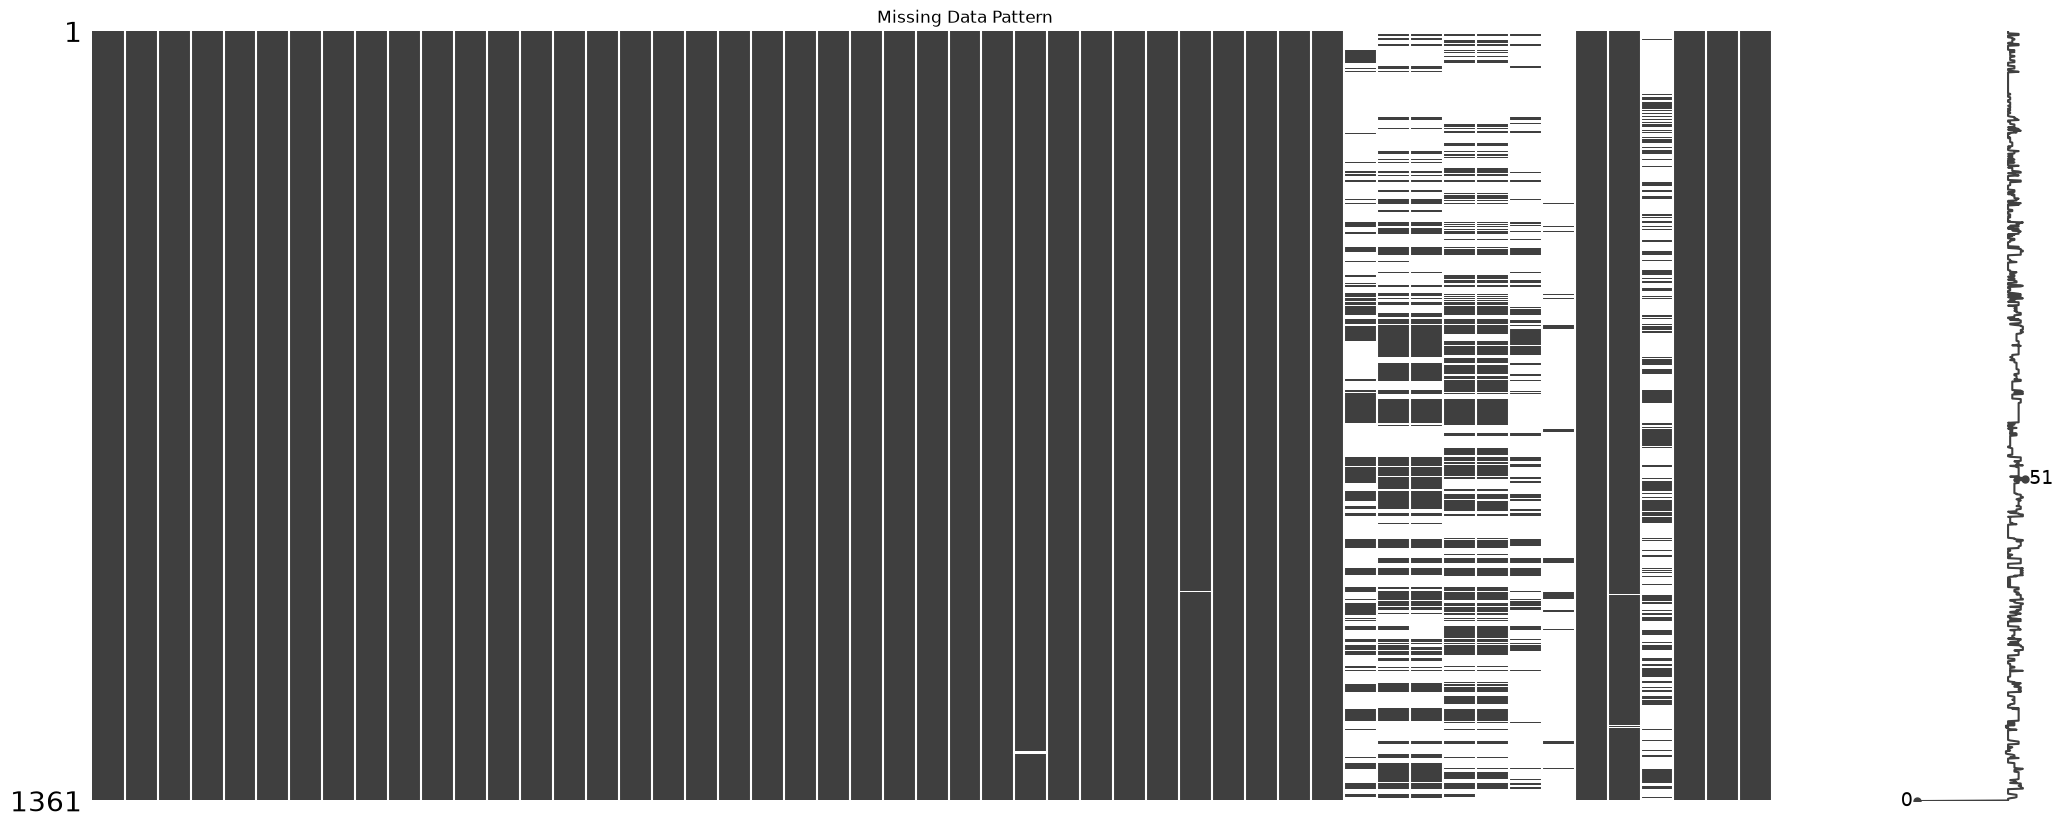

In [51]:
# Option 1: missingno matrix
msno.matrix(df)
plt.title("Missing Data Pattern")
plt.show()

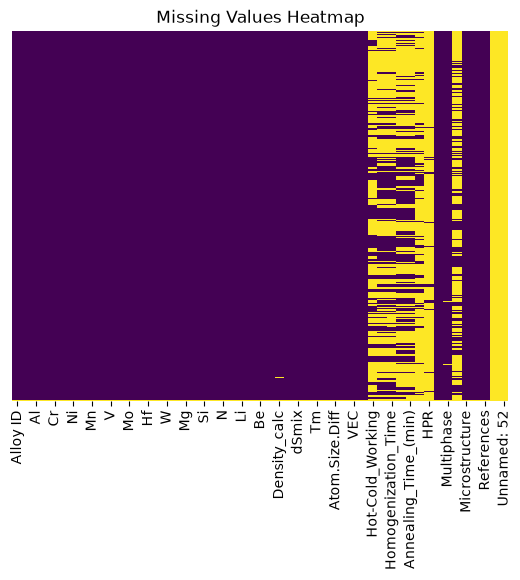

In [52]:
# Option 2: seaborn heatmap
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title("Missing Values Heatmap")
plt.show()

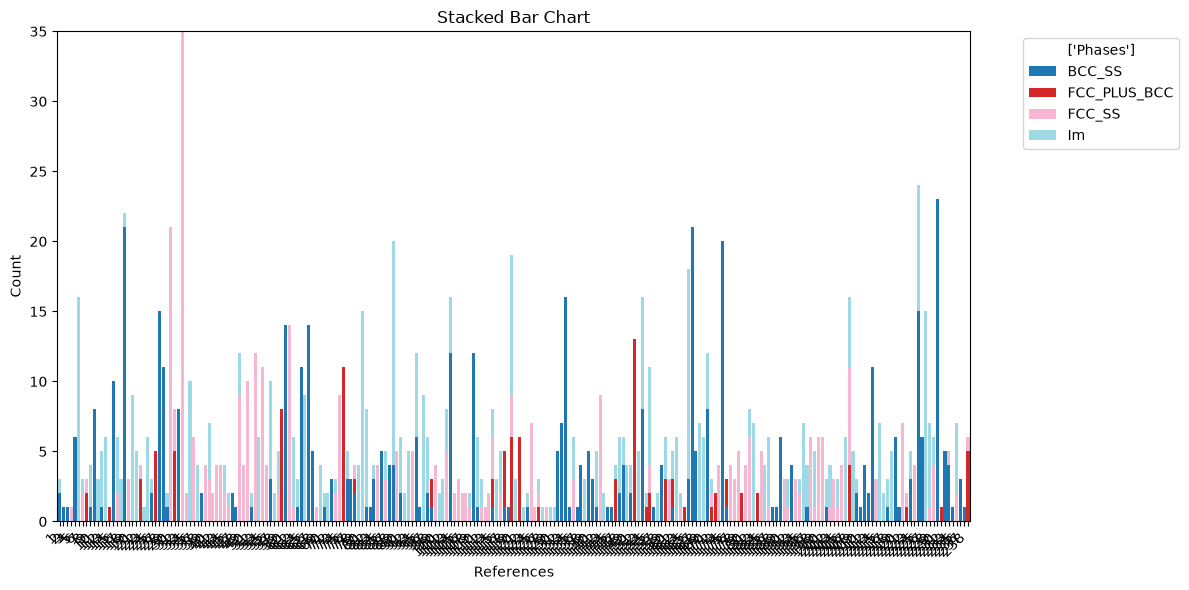

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
 
# Group by first and second columns, counting occurrences
grouped = (
    df.groupby(['References', 'Phases'])
      .size()
      .unstack(fill_value=0)
)
 
# Create stacked bar chart
ax = grouped.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    width=0.8,
    colormap='tab20'
)
 
ax.set_xticks(range(len(grouped)))
ax.set_xticklabels(range(1, len(grouped) + 1), rotation=0)

#plt.xlabel(['References'])
plt.ylabel("Count")
plt.title("Stacked Bar Chart")
plt.legend(title=['Phases'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

C:\Users\elyse\AppData\Local\Temp\ipykernel_7352\2739491496.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title=['Phases'], bbox_to_anchor=(1.05, 1), loc='upper left')


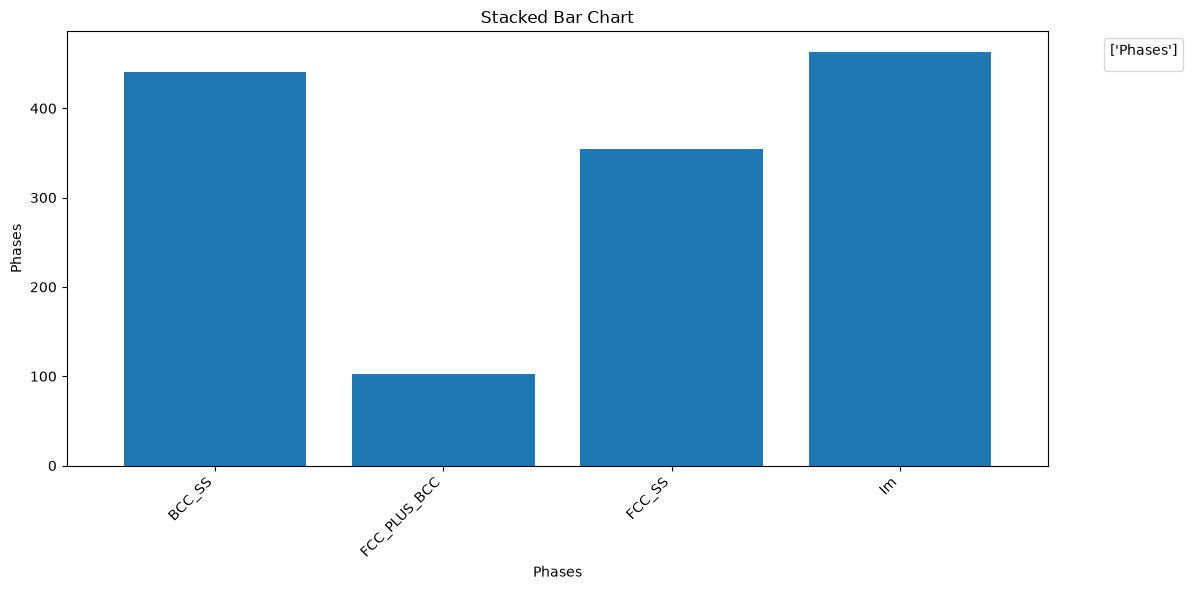

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
 
# Group by first and second columns, counting occurrences
grouped = df.groupby('Phases').size()
 
# Create stacked bar chart
ax = grouped.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    width=0.8,
    colormap='tab20'
)


#plt.xlabel(['References'])
plt.ylabel("Phases")
plt.title("Stacked Bar Chart")
plt.legend(title=['Phases'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [54]:
# Outlier Removal — Z-score
from scipy.stats import zscore
import numpy as np


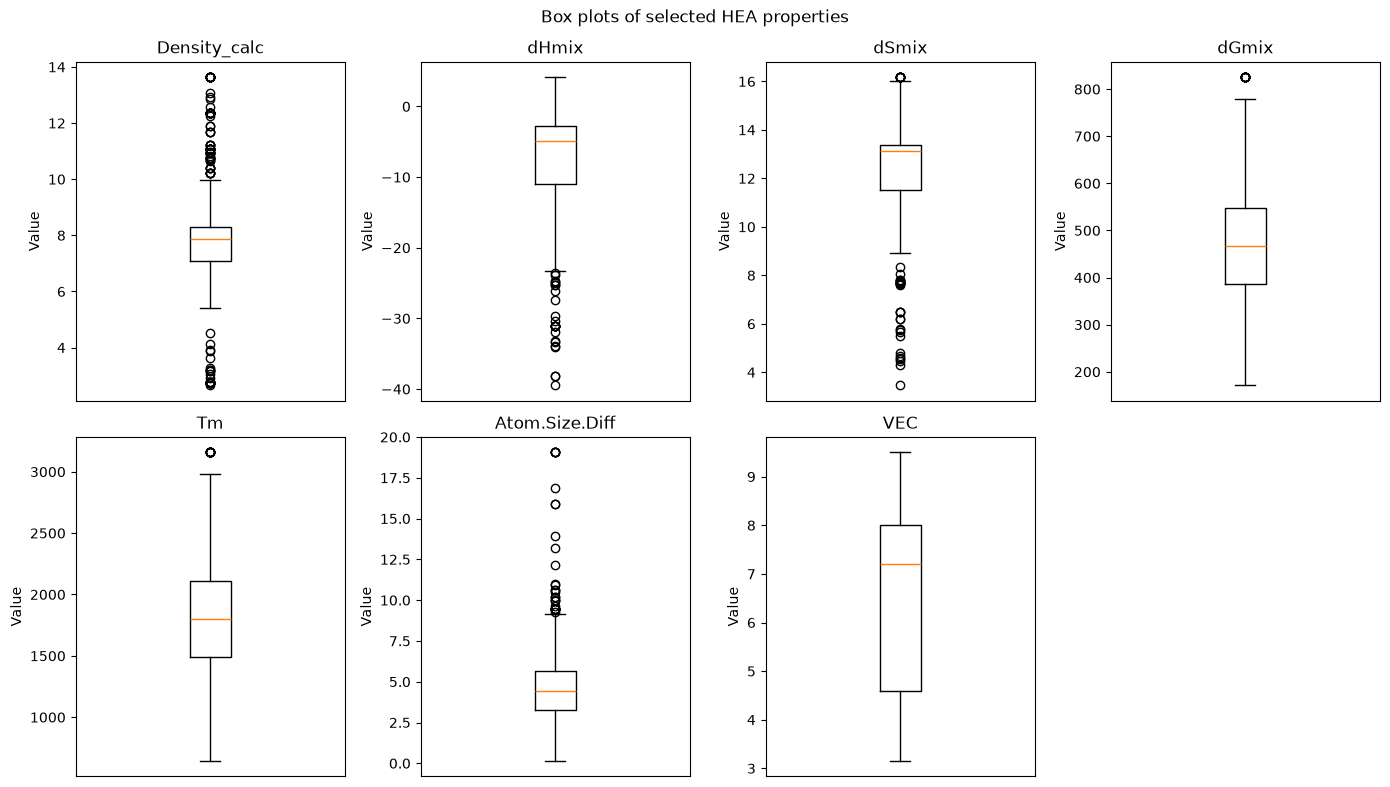

In [56]:

import matplotlib.pyplot as plt

# Choose numeric properties to inspect
features = [
    "Density_calc",
    "dHmix",
    "dSmix",
    "dGmix",
    "Tm",
    "Atom.Size.Diff",
    "VEC"
]

# Convert entries to numbers; unparseable or missing values become NaN
for column in features:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Draw a separate box plot for each property
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
axes = axes.flatten()

for ax, column in zip(axes, features):
    values = df[column].dropna()
    ax.boxplot(values)
    ax.set_title(column)
    ax.set_ylabel("Value")
    ax.set_xticks([])

# Hide the unused eighth subplot
axes[-1].set_visible(False)

plt.suptitle("Box plots of selected HEA properties")
plt.tight_layout()
plt.show()

In [57]:
# Select numeric properties to check for outliers
features = [
    "Density_calc",
    "dHmix",
    "dSmix",
    "dGmix",
    "Tm",
    "Atom.Size.Diff",
    "VEC"
]

# Work on a copy, converting any non-numeric values to NaN
df_clean = df.copy()
df_clean[features] = df_clean[features].apply(pd.to_numeric, errors="coerce")

# Calculate Z-scores for the selected properties
z_scores = (
    (df_clean[features] - df_clean[features].mean())
    / df_clean[features].std()
)

# Keep rows within ±3 standard deviations.
# Missing values are retained rather than treated as outliers.
keep_rows = z_scores.abs().le(3) | z_scores.isna()
df_clean = df_clean.loc[keep_rows.all(axis=1)].copy()

print("Original rows:", len(df))
print("Rows after outlier removal:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Original rows: 1361
Rows after outlier removal: 1292
Rows removed: 69


In [58]:
print("Removed:", len(df) - len(df_clean))
print("Remaining:", len(df_clean))

Removed: 69
Remaining: 1292


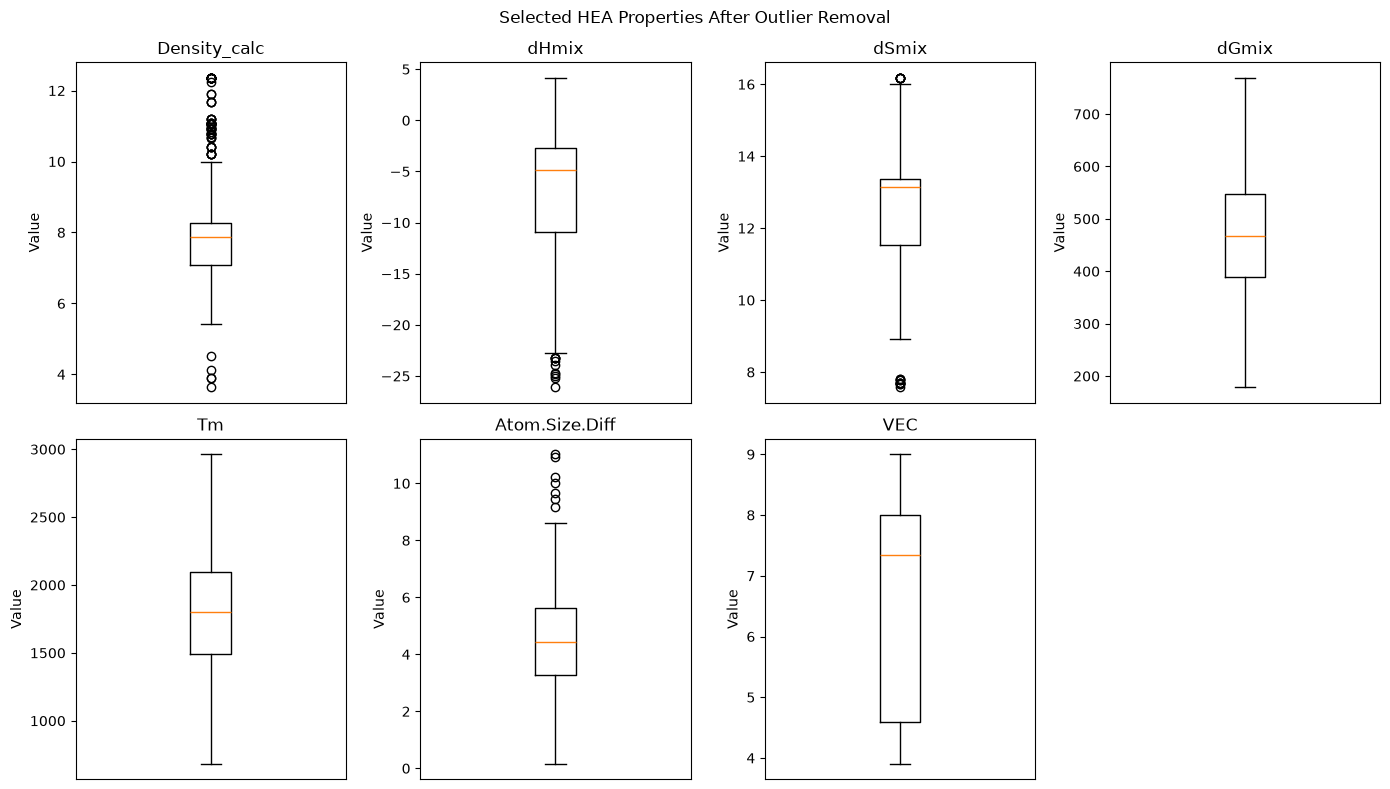

In [59]:
import matplotlib.pyplot as plt
import pandas as pd

# Use the same features as in the outlier-removal cell
features = [
    "Density_calc",
    "dHmix",
    "dSmix",
    "dGmix",
    "Tm",
    "Atom.Size.Diff",
    "VEC"
]

fig, axes = plt.subplots(2, 4, figsize=(14, 8))
axes = axes.flatten()

for ax, column in zip(axes, features):
    values = pd.to_numeric(df_clean[column], errors="coerce").dropna()
    ax.boxplot(values)
    ax.set_title(column)
    ax.set_ylabel("Value")
    ax.set_xticks([])

# There are seven features, so hide the eighth subplot
axes[-1].set_visible(False)

fig.suptitle("Selected HEA Properties After Outlier Removal")
plt.tight_layout()
plt.show()

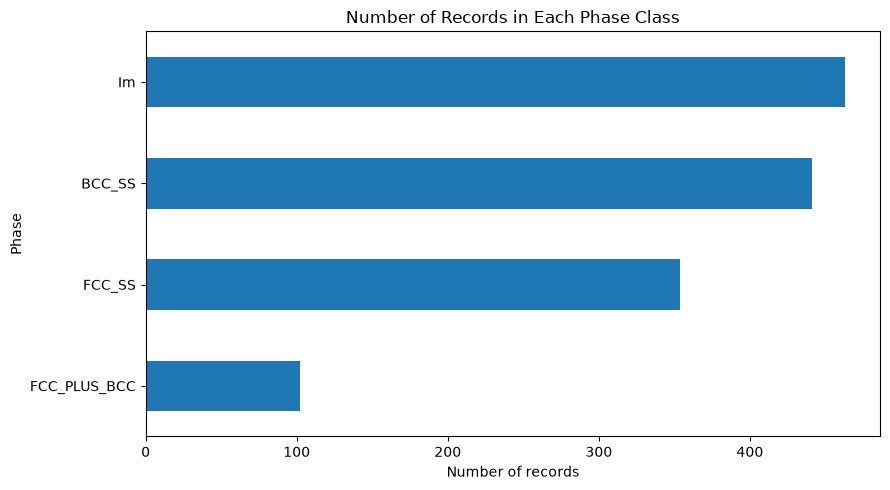

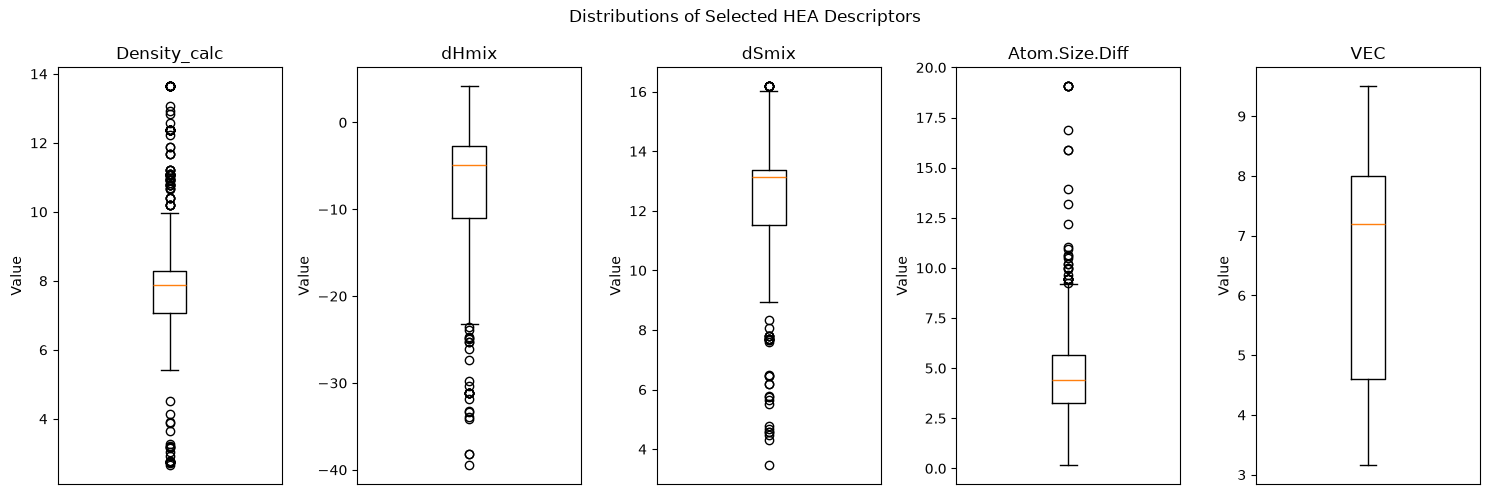

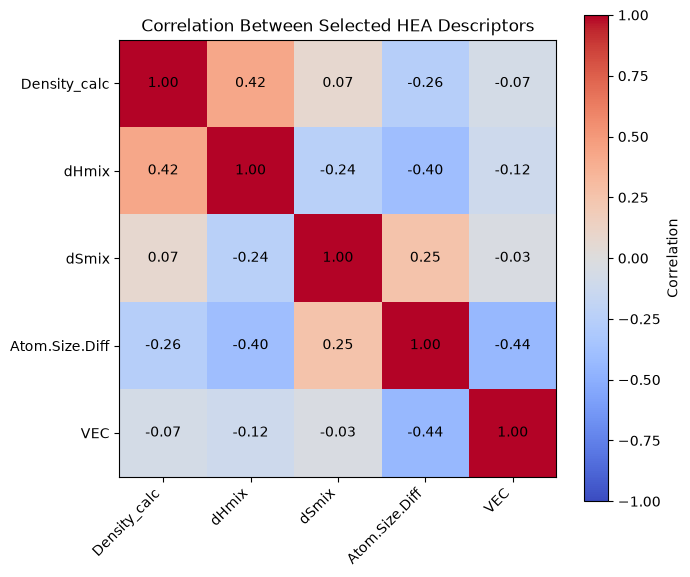

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Select a small set of relevant numeric descriptors
features = [
    "Density_calc",
    "dHmix",
    "dSmix",
    "Atom.Size.Diff",
    "VEC"
]

# Work on a copy so the original dataframe is unchanged
eda_df = df.copy()

# Convert selected columns to numeric; invalid or missing entries become NaN
eda_df[features] = eda_df[features].apply(
    pd.to_numeric, errors="coerce"
)

# -------------------------
# Plot 1: Phase class balance
# -------------------------
phase_counts = eda_df["Phases"].dropna().value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
phase_counts.plot(kind="barh", ax=ax)
ax.set_title("Number of Records in Each Phase Class")
ax.set_xlabel("Number of records")
ax.set_ylabel("Phase")
plt.tight_layout()
plt.show()

# -------------------------
# Plot 2: Feature distributions and potential outliers
# -------------------------
fig, axes = plt.subplots(1, len(features), figsize=(15, 5))

for ax, feature in zip(axes, features):
    values = eda_df[feature].dropna()
    ax.boxplot(values)
    ax.set_title(feature)
    ax.set_ylabel("Value")
    ax.set_xticks([])

fig.suptitle("Distributions of Selected HEA Descriptors")
plt.tight_layout()
plt.show()

# -------------------------
# Plot 3: Correlations between selected numeric descriptors
# -------------------------
correlation = eda_df[features].corr()

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(features)))
ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features)
ax.set_title("Correlation Between Selected HEA Descriptors")

# Show the correlation value in each cell
for row in range(len(features)):
    for col in range(len(features)):
        value = correlation.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f"{value:.2f}", ha="center", va="center")

fig.colorbar(image, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

 I selected the Phases label and five numeric descriptors—density, mixing enthalpy, mixing entropy, atomic-size difference, and valence-electron concentration—rather than plotting every column in the dataset. These descriptors capture different aspects of alloy composition and thermodynamic or electronic behaviour that may be associated with phase formation. The phase-count plot checks whether some classes are much more common than others, which could affect model training and evaluation. The box plots show the distributions and potential outliers in the selected descriptors, helping identify unusual values and differences in scale. The correlation plot shows whether any numeric descriptors are strongly related, which may indicate overlapping information. These plots will guide later checks for class imbalance, data quality, and feature preparation.

In your interpretation, describe what the plots actually show—for example, which phase classes are most or least frequent, and which descriptors have visibly unusual values. Don’t remove box-plot outliers automatically; first check whether they are data errors or plausible differences between alloys.

To cover each requirement clearly, I’d use five plots: a phase-count chart for class imbalance, histograms for distributions, box plots for potential outliers, a correlation heatmap, and a scatter plot for patterns between two descriptors.

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

features = [
    "Density_calc",
    "dHmix",
    "dSmix",
    "Atom.Size.Diff",
    "VEC"
]

# Make a copy so the original dataframe is unchanged
eda_df = df.copy()

# Clean phase labels and ensure the selected features are numeric
eda_df["Phases"] = eda_df["Phases"].astype("string").str.strip()
eda_df[features] = eda_df[features].apply(pd.to_numeric, errors="coerce")

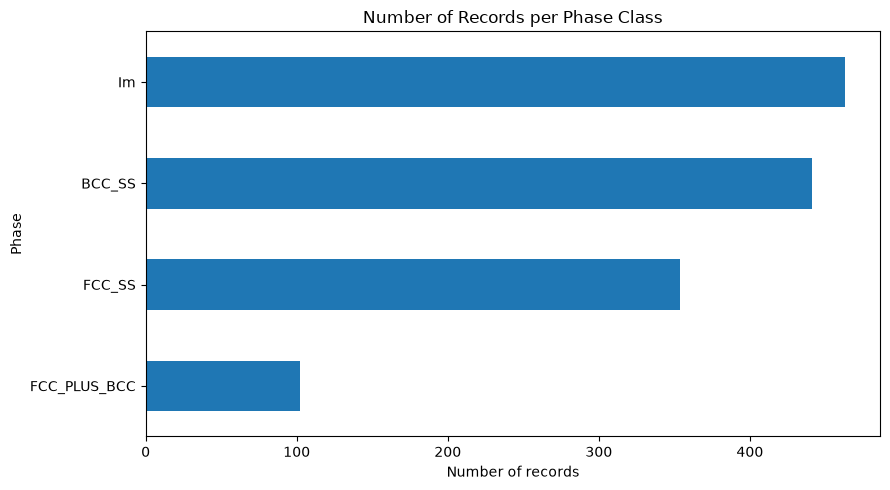

In [62]:
# Class imbalance: Count the number of records in each phase class
phase_counts = eda_df["Phases"].dropna().value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
phase_counts.plot(kind="barh", ax=ax)
ax.set_title("Number of Records per Phase Class")
ax.set_xlabel("Number of records")
ax.set_ylabel("Phase")
plt.tight_layout()
plt.show()

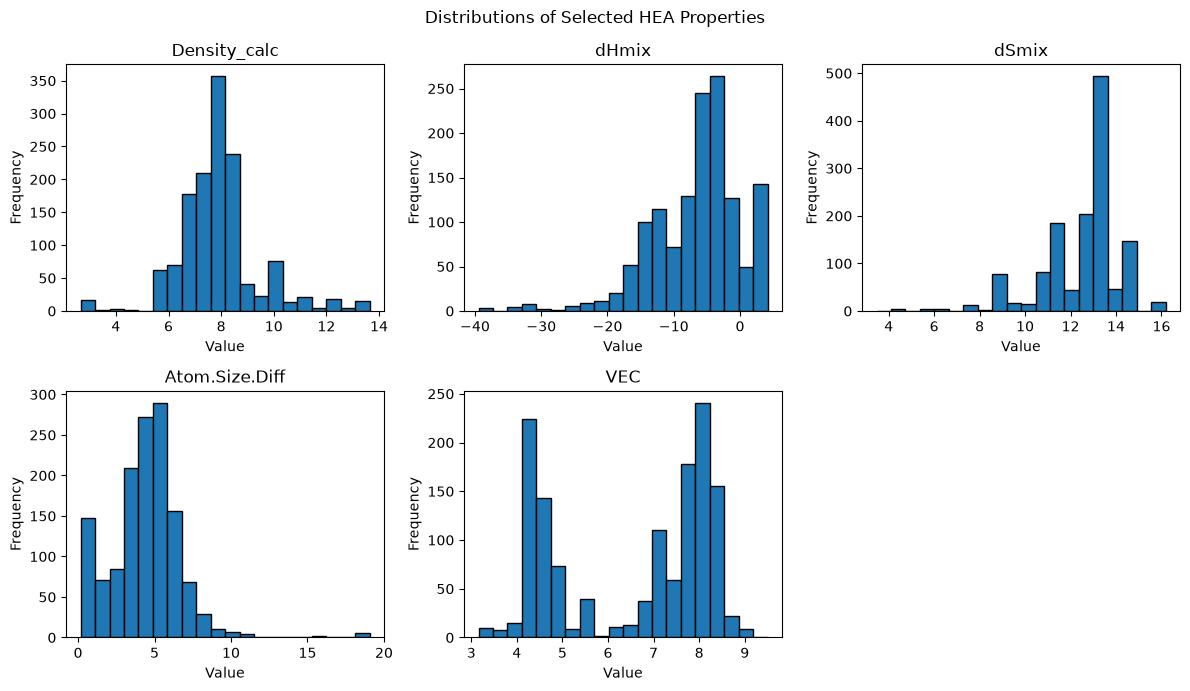

In [63]:
#Histograms of selected numeric descriptors
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    values = eda_df[feature].dropna()
    ax.hist(values, bins=20, edgecolor="black")
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

# Hide the unused sixth subplot
axes[-1].set_visible(False)

fig.suptitle("Distributions of Selected HEA Properties")
plt.tight_layout()
plt.show()

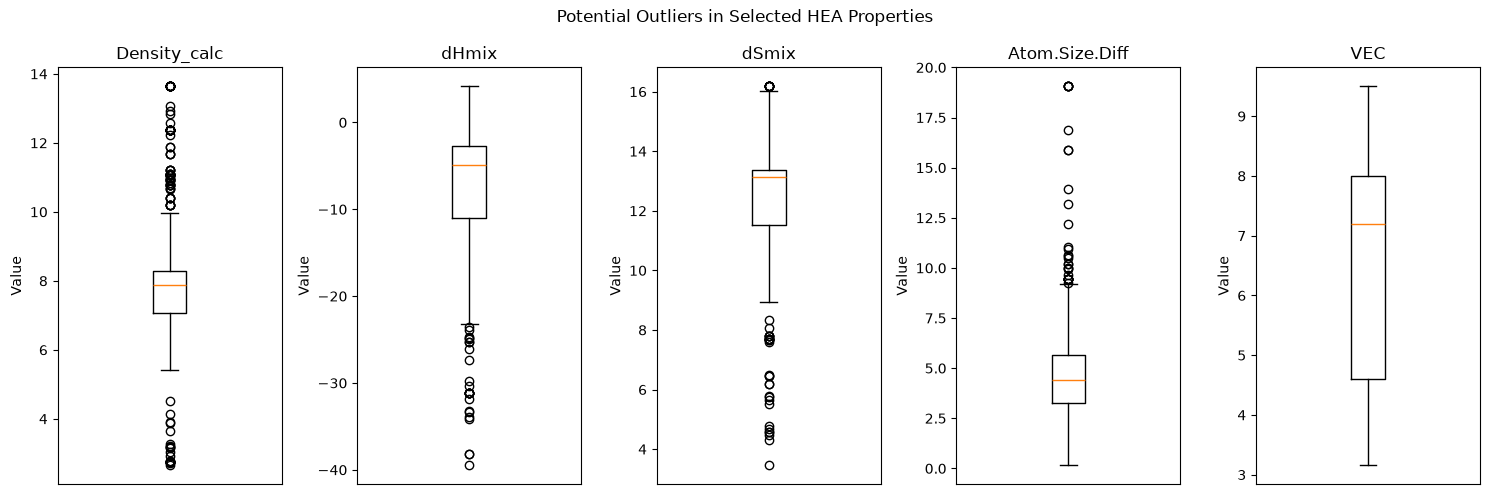

In [64]:
# Potential outliers in selected numeric descriptors
fig, axes = plt.subplots(1, len(features), figsize=(15, 5))

for ax, feature in zip(axes, features):
    values = eda_df[feature].dropna()
    ax.boxplot(values)
    ax.set_title(feature)
    ax.set_ylabel("Value")
    ax.set_xticks([])

fig.suptitle("Potential Outliers in Selected HEA Properties")
plt.tight_layout()
plt.show()

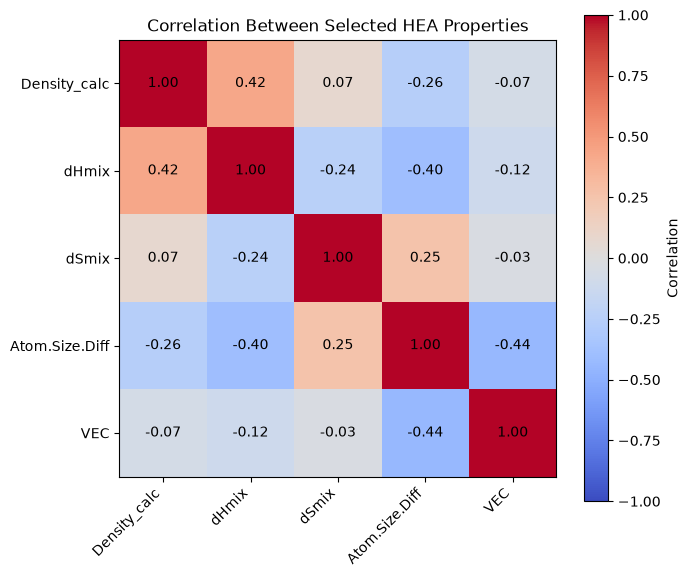

In [65]:
#Correlation heatmap of selected numeric descriptors
correlation = eda_df[features].corr()

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(features)))
ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features)
ax.set_title("Correlation Between Selected HEA Properties")

for row in range(len(features)):
    for col in range(len(features)):
        value = correlation.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f"{value:.2f}", ha="center", va="center")

fig.colorbar(image, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

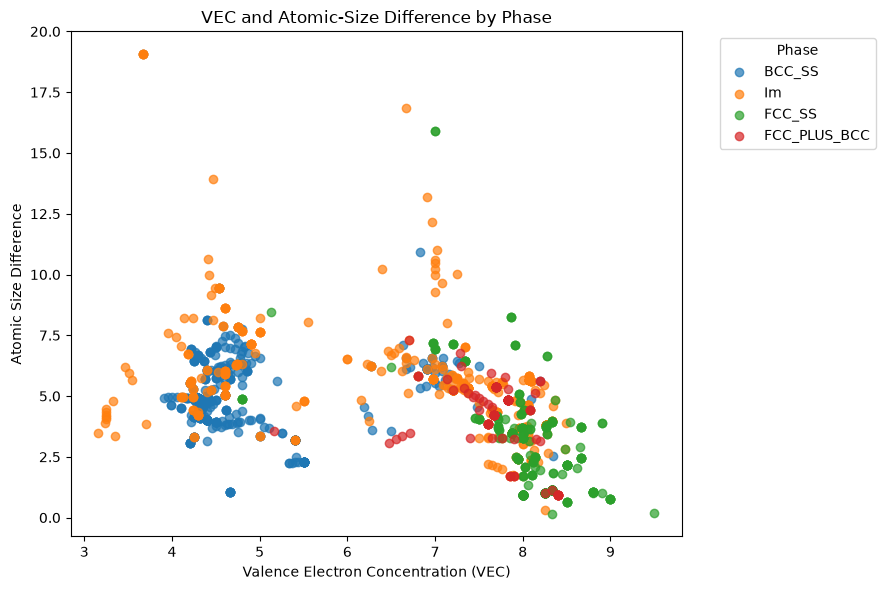

In [66]:
# Patterns: comparing two descriptors across phase classes. Shows the five most frequent phase classes, with all others grouped into "Other".
plot_df = eda_df.dropna(
    subset=["Phases", "VEC", "Atom.Size.Diff"]
).copy()

top_phases = plot_df["Phases"].value_counts().head(5).index
plot_df["Phase group"] = plot_df["Phases"].where(
    plot_df["Phases"].isin(top_phases),
    "Other"
)

fig, ax = plt.subplots(figsize=(9, 6))

for phase in plot_df["Phase group"].unique():
    group = plot_df[plot_df["Phase group"] == phase]
    ax.scatter(
        group["VEC"],
        group["Atom.Size.Diff"],
        label=phase,
        alpha=0.7
    )

ax.set_title("VEC and Atomic-Size Difference by Phase")
ax.set_xlabel("Valence Electron Concentration (VEC)")
ax.set_ylabel("Atomic Size Difference")
ax.legend(title="Phase", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()